#***GÖREV 1***

In [2]:
%pip install -q datasets tiktoken

In [3]:
import os
import numpy as np
import torch
import tiktoken

from datasets import load_dataset

data_root = "/content/edu_fineweb20M"
os.makedirs(data_root, exist_ok=True)

shard_size = 1_000_000
num_shards = 20

enc = tiktoken.get_encoding("gpt2")
eot = enc.eot_token

fw = load_dataset(
    "HuggingFaceFW/fineweb-edu",
    name="sample-10BT",
    split="train",
    streaming=True,
)

README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

In [4]:
def tokenize(doc):
    tokens = [eot]
    tokens.extend(enc.encode_ordinary(doc["text"]))

    tokens = np.array(tokens)
    assert tokens.min() >= 0 and tokens.max() < 2**16

    return tokens.astype(np.uint16)

In [5]:
assert not any(
    name.endswith(".npy") for name in os.listdir(data_root)
), "Token dosyaları zaten var. Hazırlama tamamlandıysa bu hücreyi atla."

all_tokens = np.empty(shard_size, dtype=np.uint16)

shard_index = 0
token_count = 0

for doc in fw:
    tokens = tokenize(doc)
    offset = 0

    while offset < len(tokens) and shard_index < num_shards:
        n = min(shard_size - token_count, len(tokens) - offset)

        all_tokens[token_count:token_count + n] = tokens[offset:offset + n]

        token_count += n
        offset += n

        if token_count == shard_size:
            split = "val" if shard_index == 0 else "train"

            filename = os.path.join(
                data_root,
                f"edufineweb_{split}_{shard_index:06d}.npy",
            )

            np.save(filename, all_tokens)
            print(f"{os.path.basename(filename)}: {token_count:,} token")

            shard_index += 1
            token_count = 0

            # Doğrulamadaki belgenin devamını eğitime alma.
            if shard_index == 1:
                break

    if shard_index == num_shards:
        break

assert shard_index == num_shards, "Veri hazırlama tamamlanmadı."

edufineweb_val_000000.npy: 1,000,000 token
edufineweb_train_000001.npy: 1,000,000 token
edufineweb_train_000002.npy: 1,000,000 token
edufineweb_train_000003.npy: 1,000,000 token
edufineweb_train_000004.npy: 1,000,000 token
edufineweb_train_000005.npy: 1,000,000 token
edufineweb_train_000006.npy: 1,000,000 token
edufineweb_train_000007.npy: 1,000,000 token
edufineweb_train_000008.npy: 1,000,000 token
edufineweb_train_000009.npy: 1,000,000 token
edufineweb_train_000010.npy: 1,000,000 token
edufineweb_train_000011.npy: 1,000,000 token
edufineweb_train_000012.npy: 1,000,000 token
edufineweb_train_000013.npy: 1,000,000 token
edufineweb_train_000014.npy: 1,000,000 token
edufineweb_train_000015.npy: 1,000,000 token
edufineweb_train_000016.npy: 1,000,000 token
edufineweb_train_000017.npy: 1,000,000 token
edufineweb_train_000018.npy: 1,000,000 token
edufineweb_train_000019.npy: 1,000,000 token


In [6]:
def load_tokens(filename):
    tokens = np.load(filename).astype(np.int32)
    return torch.tensor(tokens, dtype=torch.long)


class DataLoaderLite:
    def __init__(self, B, T, split):
        self.B = B
        self.T = T

        assert split in ("train", "val")

        self.shards = sorted(
            os.path.join(data_root, name)
            for name in os.listdir(data_root)
            if name.startswith(f"edufineweb_{split}_")
            and name.endswith(".npy")
        )

        assert len(self.shards) > 0, "Token dosyası bulunamadı."

        print(f"{split}: {len(self.shards)} dosya bulundu.")
        self.reset()

    def reset(self):
        self.current_shard = 0
        self.current_position = 0
        self.tokens = load_tokens(self.shards[self.current_shard])

    def next_batch(self):
        B, T = self.B, self.T
        start = self.current_position

        buf = self.tokens[start:start + B * T + 1]

        x = buf[:-1].view(B, T)
        y = buf[1:].view(B, T)

        self.current_position += B * T

        if self.current_position + B * T + 1 > len(self.tokens):
            self.current_shard = (
                self.current_shard + 1
            ) % len(self.shards)

            self.tokens = load_tokens(self.shards[self.current_shard])
            self.current_position = 0

        return x, y

In [7]:
train_loader = DataLoaderLite(B=2, T=256, split="train")
val_loader = DataLoaderLite(B=2, T=256, split="val")

for split, loader in [("train", train_loader), ("val", val_loader)]:
    total_tokens = sum(
        np.load(path, mmap_mode="r").size
        for path in loader.shards
    )
    print(f"{split} token sayısı: {total_tokens:,}")

x, y = train_loader.next_batch()

print("\nx boyutu:", x.shape)
print("y boyutu:", y.shape)
print("İlk 10 giriş tokenı:", x[0, :10].tolist())
print("İlk 10 hedef token:", y[0, :10].tolist())

assert torch.equal(x[:, 1:], y[:, :-1])

print("\nİlk giriş metni:")
print(enc.decode(x[0].tolist()))

x_val, y_val = val_loader.next_batch()
print("\nDoğrulama batch boyutu:", x_val.shape)

train_loader.reset()
val_loader.reset()

train: 19 dosya bulundu.
val: 1 dosya bulundu.
train token sayısı: 19,000,000
val token sayısı: 1,000,000

x boyutu: torch.Size([2, 256])
y boyutu: torch.Size([2, 256])
İlk 10 giriş tokenı: [50256, 43460, 560, 4992, 14962, 198, 26437, 26658, 1675, 19430]
İlk 10 hedef token: [43460, 560, 4992, 14962, 198, 26437, 26658, 1675, 19430, 317]

İlk giriş metni:
<|endoftext|>Literary Research Paper
Simple Ways To Write A Literary Research Paper
Unlike most other research papers, a literary research paper generally requires an argumentative style of writing rather than a descriptive style. Loads of support content would be available to support an opinion, but knowing how to present it is a totally different ball game.
The topics in these research papers may vary from character analysis of a fictitious character to analyzing the change in writing styles of different authors. Different alternative endings may have to be suggested for a plot. For instance, the assignment could be to write a critica

# ***GÖREV 2***

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

n_embd = 768
n_head = 12
n_layer = 12
block_size = 1024
vocab_size = 50257
dropout = 0.0


class MultiHeadAttention(nn.Module):
    def __init__(self):
        super().__init__()

        self.n_head = n_head

        self.c_attn = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)

        self.attn_dropout = nn.Dropout(dropout)
        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "tril",
            torch.tril(torch.ones(block_size, block_size)),
            persistent=False,
        )

    def forward(self, x):
        B, T, C = x.shape
        head_size = C // self.n_head

        q, k, v = self.c_attn(x).split(C, dim=-1)

        q = q.view(B, T, self.n_head, head_size).transpose(1, 2)
        k = k.view(B, T, self.n_head, head_size).transpose(1, 2)
        v = v.view(B, T, self.n_head, head_size).transpose(1, 2)

        wei = q @ k.transpose(-2, -1) * head_size**-0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = F.softmax(wei, dim=-1)
        wei = self.attn_dropout(wei)

        out = wei @ v
        out = out.transpose(1, 2).contiguous().view(B, T, C)

        return self.dropout(self.proj(out))


class FeedFoward(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(approximate="tanh"),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self):
        super().__init__()

        self.sa = MultiHeadAttention()
        self.ffwd = FeedFoward()

        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))

        return x


class GPTLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)

        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.Sequential(
            *[Block() for _ in range(n_layer)]
        )

        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)

        self.lm_head.weight = self.token_embedding_table.weight

    def forward(self, idx, targets=None):
        B, T = idx.shape

        assert T <= self.position_embedding_table.num_embeddings

        positions = torch.arange(T, device=idx.device)

        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(positions)

        x = self.dropout(tok_emb + pos_emb)
        x = self.blocks(x)
        x = self.ln_f(x)

        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1),
            )

        return logits, loss

In [9]:
import math
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(1337)

device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"


In [10]:
n_embd = 768
n_head = 12
n_layer = 12
block_size = 1024
vocab_size = enc.n_vocab
dropout = 0.0

model = GPTLanguageModel()
model.lm_head.weight = model.token_embedding_table.weight

for name, p in model.named_parameters():
    if p.dim() == 2:
        std = 0.02

        if name.endswith(("sa.proj.weight", "ffwd.net.2.weight")):
            std *= (2 * n_layer) ** -0.5

        nn.init.normal_(p, mean=0.0, std=std)

    elif name.endswith("bias"):
        nn.init.zeros_(p)

    else:
        nn.init.ones_(p)

model = model.to(device)

B, T = 2, 256

train_loader = DataLoaderLite(B, T, split="train")
val_loader = DataLoaderLite(B, T, split="val")


train_eval_loader = DataLoaderLite(B, T, split="train")

print("Cihaz:", device)
print("Parametre sayısı:", sum(p.numel() for p in model.parameters()))

train: 19 dosya bulundu.
val: 1 dosya bulundu.
train: 19 dosya bulundu.
Cihaz: cuda
Parametre sayısı: 124439808


In [11]:
max_steps = 500
eval_interval = 100
eval_iters = 20
grad_accum_steps = 8

max_lr = 6e-4
min_lr = 6e-5
warmup_steps = 50

decay_params = [p for p in model.parameters() if p.dim() == 2]
no_decay_params = [p for p in model.parameters() if p.dim() < 2]

optimizer = torch.optim.AdamW(
    [
        {"params": decay_params, "weight_decay": 0.1},
        {"params": no_decay_params, "weight_decay": 0.0},
    ],
    lr=max_lr,
    betas=(0.9, 0.95),
    eps=1e-8,
    fused=use_amp,
)

scaler = torch.amp.GradScaler(
    "cuda", enabled=use_amp, init_scale=128
)


def get_lr(step):
    update = step + 1

    if update <= warmup_steps:
        return max_lr * update / warmup_steps

    ratio = (update - warmup_steps) / (max_steps - warmup_steps)
    ratio = min(ratio, 1.0)

    return min_lr + 0.5 * (1 + math.cos(math.pi * ratio)) * (
        max_lr - min_lr
    )

In [12]:
@torch.no_grad()
def estimate_loss():
    model.eval()
    losses = {}

    for split, loader in [
        ("train", train_eval_loader),
        ("val", val_loader),
    ]:
        loader.reset()
        total_loss = torch.zeros((), device=device)

        for _ in range(eval_iters):
            x, y = loader.next_batch()
            x, y = x.to(device), y.to(device)

            with torch.autocast(
                device_type=device,
                dtype=torch.float16,
                enabled=use_amp,
            ):
                _, loss = model(x, y)

            total_loss += loss.detach()

        losses[split] = (total_loss / eval_iters).item()

    model.train()
    return losses

In [13]:
@torch.no_grad()
def generate_sample():
    model.eval()

    prompt = "Hello, I'm a language model,"
    x = torch.tensor(
        enc.encode(prompt),
        dtype=torch.long,
        device=device,
    ).unsqueeze(0)

    sample_rng = torch.Generator(device=device)
    sample_rng.manual_seed(42)

    for _ in range(40):
        with torch.autocast(
            device_type=device,
            dtype=torch.float16,
            enabled=use_amp,
        ):
            logits, _ = model(x[:, -block_size:])

        logits = logits[:, -1, :enc.n_vocab].float()

        top_logits, top_indices = torch.topk(logits, k=50, dim=-1)
        probs = F.softmax(top_logits, dim=-1)

        choice = torch.multinomial(
            probs,
            num_samples=1,
            generator=sample_rng,
        )

        next_token = torch.gather(top_indices, 1, choice)
        x = torch.cat((x, next_token), dim=1)

        if next_token.item() == eot:
            break

    text = enc.decode(x[0].tolist())
    model.train()

    return text

In [14]:
history = {"step": [], "train": [], "val": []}
samples = []


def evaluate(step):
    losses = estimate_loss()
    text = generate_sample()

    history["step"].append(step)
    history["train"].append(losses["train"])
    history["val"].append(losses["val"])
    samples.append((step, text))

    print(
        f"\nAdım {step} | "
        f"train: {losses['train']:.4f} | "
        f"val: {losses['val']:.4f}"
    )
    print(text)
    print("-" * 60)


train_loader.reset()
evaluate(0)

step = 0
skipped_steps = 0

while step < max_steps:
    model.train()
    optimizer.zero_grad(set_to_none=True)

    lr = get_lr(step)
    for group in optimizer.param_groups:
        group["lr"] = lr

    loss_accum = torch.zeros((), device=device)

    for _ in range(grad_accum_steps):
        x, y = train_loader.next_batch()
        x, y = x.to(device), y.to(device)

        with torch.autocast(
            device_type=device,
            dtype=torch.float16,
            enabled=use_amp,
        ):
            _, loss = model(x, y)
            loss = loss / grad_accum_steps

        loss_accum += loss.detach()
        scaler.scale(loss).backward()

    scaler.unscale_(optimizer)
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

    old_scale = scaler.get_scale()
    scaler.step(optimizer)
    scaler.update()

    if scaler.get_scale() < old_scale:
        skipped_steps += 1
        print("FP16 taşması: optimizer güncellemesi atlandı.")

        if skipped_steps >= 10:
            raise RuntimeError("Tekrarlayan FP16 taşması; eğitimi kontrol et.")

        continue

    step += 1

    if step == 1 or step % 10 == 0:
        print(
            f"Adım {step}/{max_steps} | "
            f"batch loss: {loss_accum.item():.4f} | "
            f"norm: {norm.item():.4f} | lr: {lr:.6f}"
        )

    if step % eval_interval == 0 or step == max_steps:
        evaluate(step)

print("\nEğitim tamamlandı.")
print("Atlanan FP16 güncellemesi:", skipped_steps)


Adım 0 | train: 11.0062 | val: 11.0094
Hello, I'm a language model, ascended correl FoolREFJD debutedVector cartel assassination 500 hints Sens ][ downloadable Seraph Bram initializationwine Spa outlawedvmproperty eleven SERople obligations obligations trem haircmoreChristian OwlMuslims Mars Scaleuces Acqu grizz conference advisor
------------------------------------------------------------
Adım 1/500 | batch loss: 10.9998 | norm: 18.6612 | lr: 0.000012
Adım 10/500 | batch loss: 9.2305 | norm: 2.5427 | lr: 0.000120
Adım 20/500 | batch loss: 8.7494 | norm: 1.6171 | lr: 0.000240
Adım 30/500 | batch loss: 7.8188 | norm: 1.2649 | lr: 0.000360
Adım 40/500 | batch loss: 7.9946 | norm: 1.5187 | lr: 0.000480
Adım 50/500 | batch loss: 6.9385 | norm: 1.5605 | lr: 0.000600
Adım 60/500 | batch loss: 7.5648 | norm: 1.5467 | lr: 0.000599
Adım 70/500 | batch loss: 7.4135 | norm: 1.2370 | lr: 0.000597
Adım 80/500 | batch loss: 7.7638 | norm: 1.2984 | lr: 0.000594
Adım 90/500 | batch loss: 7.0789 | no

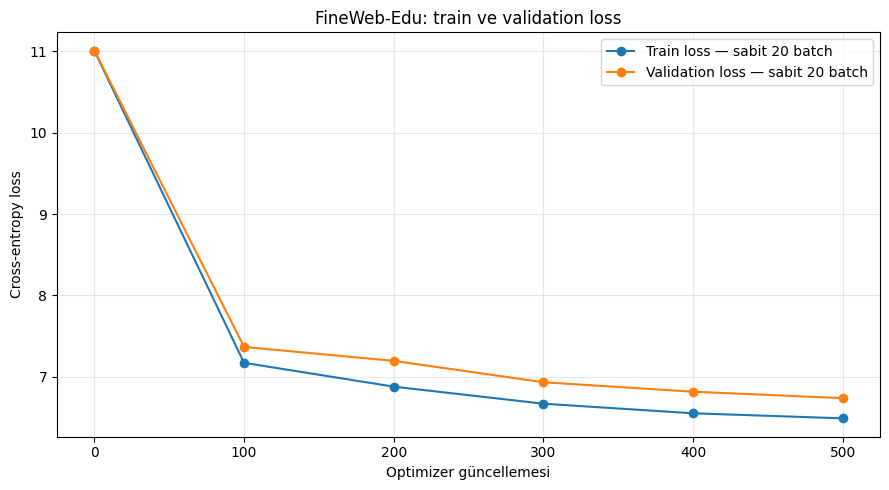

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["step"],
    history["train"],
    marker="o",
    label="Train loss — sabit 20 batch",
)

plt.plot(
    history["step"],
    history["val"],
    marker="o",
    label="Validation loss — sabit 20 batch",
)

plt.xlabel("Optimizer güncellemesi")
plt.ylabel("Cross-entropy loss")
plt.title("FineWeb-Edu: train ve validation loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ***GÖREV 3***

In [17]:
import time
import os

assert device == "cuda", "Bu koşu için Colab GPU oturumunu aç."

run_seconds = 15 * 60
eval_interval_long = 250
grad_accum_steps = 8

previous_steps = 500
previous_tokens = 2_048_000

tokens_per_step = B * T * grad_accum_steps

save_dir = "/content/gpt2_long_run"
os.makedirs(save_dir, exist_ok=True)


def forward_loss(x, y):
    return model(x, y)[1]


train_forward = torch.compile(forward_loss, fullgraph=True)

model.train()
train_eval_loader.reset()

x, y = train_eval_loader.next_batch()
x, y = x.to(device), y.to(device)

torch.cuda.synchronize()
t0 = time.perf_counter()

for _ in range(3):
    optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=torch.float16):
        loss = train_forward(x, y) / grad_accum_steps

    scaler.scale(loss).backward()

optimizer.zero_grad(set_to_none=True)
torch.cuda.synchronize()
warmup_seconds = time.perf_counter() - t0
warmup_seconds_lr = 2 * 60

print("GPU:", torch.cuda.get_device_name())
print("Bir güncellemedeki hedef token:", tokens_per_step)
print(f"Derleme ve ısınma: {warmup_seconds:.2f} saniye")

GPU: Tesla T4
Bir güncellemedeki hedef token: 4096
Derleme ve ısınma: 2.21 saniye


In [19]:
warmup_seconds_lr = 5 * 60
max_lr_long = 6e-4
min_lr_long = 6e-5


def get_lr_long(elapsed):
    if elapsed < warmup_seconds_lr:
        ratio = elapsed / warmup_seconds_lr

        return min_lr_long + ratio * (
            max_lr_long - min_lr_long
        )

    ratio = (
        (elapsed - warmup_seconds_lr)
        / (run_seconds - warmup_seconds_lr)
    )
    ratio = min(max(ratio, 0.0), 1.0)

    return min_lr_long + 0.5 * (
        1 + math.cos(math.pi * ratio)
    ) * (max_lr_long - min_lr_long)

In [20]:
long_history = {
    "step": [],
    "minutes": [],
    "train": [],
    "val": [],
}

long_samples = []


def evaluate_long(step, minutes):
    losses = estimate_loss()
    text = generate_sample()

    long_history["step"].append(previous_steps + step)
    long_history["minutes"].append(minutes)
    long_history["train"].append(losses["train"])
    long_history["val"].append(losses["val"])

    long_samples.append({
        "step": previous_steps + step,
        "minutes": minutes,
        "text": text,
    })

    print(
        f"\nToplam adım {previous_steps + step} | "
        f"{minutes:.1f} dakika | "
        f"train: {losses['train']:.4f} | "
        f"val: {losses['val']:.4f}"
    )
    print(text)
    print("-" * 60)

    with open(
        os.path.join(save_dir, "samples.txt"),
        "a",
        encoding="utf-8",
    ) as f:
        f.write(
            f"\nAdım {previous_steps + step} "
            f"| {minutes:.1f} dakika\n{text}\n"
        )


evaluate_long(step=0, minutes=0.0)


Toplam adım 500 | 0.0 dakika | train: 6.4898 | val: 6.7378
Hello, I'm a language model, has not.
- but the
Bemensa. We the time. This is an other in the body who are the future of a work's own information in the state
The body
------------------------------------------------------------


In [21]:
def save_checkpoint():
    checkpoint = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),

        "config": {
            "n_embd": n_embd,
            "n_head": n_head,
            "n_layer": n_layer,
            "block_size": block_size,
            "vocab_size": model.lm_head.out_features,
            "dropout": dropout,
        },

        "step": previous_steps + step,
        "successful_tokens": previous_tokens + trained_tokens,
        "processed_tokens_this_run": processed_tokens,

        "loader_shard": train_loader.current_shard,
        "loader_position": train_loader.current_position,

        "elapsed_seconds": time.perf_counter() - run_start,
        "training_seconds": training_seconds,

        "history": long_history,
        "samples": long_samples,

        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state(),
    }

    path = os.path.join(save_dir, "checkpoint_last.pt")
    torch.save(checkpoint, path)

    print("Checkpoint kaydedildi.")

In [22]:
step = 0
processed_tokens = 0
trained_tokens = 0

training_seconds = 0.0
skipped_steps = 0
consecutive_skips = 0
last_batch_loss = None

torch.cuda.synchronize()
run_start = time.perf_counter()

while time.perf_counter() - run_start < run_seconds:
    model.train()

    elapsed = time.perf_counter() - run_start
    lr = get_lr_long(elapsed)

    for group in optimizer.param_groups:
        group["lr"] = lr

    torch.cuda.synchronize()
    step_start = time.perf_counter()

    optimizer.zero_grad(set_to_none=True)
    loss_accum = torch.zeros((), device=device)

    for _ in range(grad_accum_steps):
        x, y = train_loader.next_batch()
        x, y = x.to(device), y.to(device)

        with torch.autocast("cuda", dtype=torch.float16):
            loss = train_forward(x, y)
            loss = loss / grad_accum_steps

        loss_accum += loss.detach()
        scaler.scale(loss).backward()

    scaler.unscale_(optimizer)
    norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(), 1.0
    )

    old_scale = scaler.get_scale()
    scaler.step(optimizer)
    scaler.update()

    torch.cuda.synchronize()
    dt = time.perf_counter() - step_start

    training_seconds += dt
    processed_tokens += tokens_per_step

    if scaler.get_scale() < old_scale:
        skipped_steps += 1
        consecutive_skips += 1

        print("FP16 taşması: güncelleme atlandı.")

        if consecutive_skips >= 10:
            save_checkpoint()
            raise RuntimeError("Arka arkaya 10 FP16 taşması oluştu.")

        continue

    consecutive_skips = 0
    step += 1
    trained_tokens += tokens_per_step
    last_batch_loss = loss_accum.item()

    if step == 1 or step % 50 == 0:
        minutes = (time.perf_counter() - run_start) / 60
        tokens_per_second = processed_tokens / training_seconds

        print(
            f"Adım {previous_steps + step} | "
            f"{minutes:.1f} dk | "
            f"loss: {last_batch_loss:.4f} | "
            f"{tokens_per_second:,.0f} token/s | "
            f"lr: {lr:.6f}"
        )

    if step % eval_interval_long == 0:
        minutes = (time.perf_counter() - run_start) / 60
        evaluate_long(step, minutes)
        save_checkpoint()

# Son model durumunu da ölç.
if long_history["step"][-1] != previous_steps + step:
    minutes = (time.perf_counter() - run_start) / 60
    evaluate_long(step, minutes)

save_checkpoint()

wall_seconds = time.perf_counter() - run_start

print("\n--- KOŞU SONUCU ---")
print(f"Derleme ve ısınma: {warmup_seconds:.2f} saniye")
print(f"Toplam koşu süresi: {wall_seconds / 60:.2f} dakika")
print(f"Eğitim adımlarında geçen süre: {training_seconds / 60:.2f} dakika")
print(f"Bu koşudaki başarılı güncelleme: {step:,}")

print(f"\nBu koşuda işlenen hedef token: {processed_tokens:,}")
print(f"Başarılı güncellemelerdeki hedef token: {trained_tokens:,}")
print(f"Önceki görev dahil başarılı hedef token: {previous_tokens + trained_tokens:,}")

print(f"\nEğitim hızı: {processed_tokens / training_seconds:,.0f} token/s")
print(f"Ölçüm ve kayıtlar dahil hız: {processed_tokens / wall_seconds:,.0f} token/s")

if last_batch_loss is not None:
    print(f"\nSon eğitim güncellemesinin loss'u: {last_batch_loss:.4f}")

print(f"Sabit train bölümündeki son loss: {long_history['train'][-1]:.4f}")
print(f"Sabit val bölümündeki son loss: {long_history['val'][-1]:.4f}")
print(f"Atlanan FP16 güncellemesi: {skipped_steps}")

Adım 501 | 0.0 dk | loss: 6.5523 | 10,230 token/s | lr: 0.000060
Adım 550 | 0.3 dk | loss: 7.0074 | 12,165 token/s | lr: 0.000090
Adım 600 | 0.6 dk | loss: 6.5649 | 12,130 token/s | lr: 0.000120
Adım 650 | 0.9 dk | loss: 6.7600 | 12,074 token/s | lr: 0.000151
Adım 700 | 1.1 dk | loss: 6.5091 | 12,023 token/s | lr: 0.000182
Adım 750 | 1.4 dk | loss: 6.4653 | 11,985 token/s | lr: 0.000214

Toplam adım 750 | 1.4 dakika | train: 6.4153 | val: 6.6780
Hello, I'm a language model, while you were still not.<|endoftext|>
------------------------------------------------------------
Checkpoint kaydedildi.
Adım 800 | 2.0 dk | loss: 6.5885 | 11,959 token/s | lr: 0.000272
Adım 850 | 2.3 dk | loss: 6.7074 | 11,934 token/s | lr: 0.000304
Adım 900 | 2.6 dk | loss: 6.7285 | 11,907 token/s | lr: 0.000335
Adım 950 | 2.8 dk | loss: 6.4302 | 11,879 token/s | lr: 0.000367
Adım 1000 | 3.1 dk | loss: 6.6282 | 11,852 token/s | lr: 0.000399

Toplam adım 1000 | 3.1 dakika | train: 6.4083 | val: 6.6566
Hello, I'm 

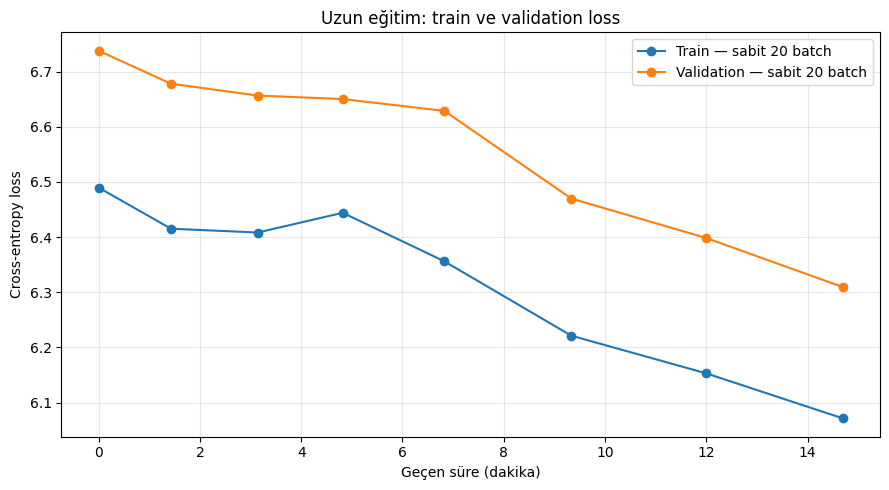


Adım 500 | 0.0 dakika
Hello, I'm a language model, has not.
- but the
Bemensa. We the time. This is an other in the body who are the future of a work's own information in the state
The body
------------------------------------------------------------

Adım 1500 | 6.8 dakika
Hello, I'm a language model, and the most important. There of its an interesting of the time at many types of all some time, if you. To the time. Now the past more more as in the end up, if
------------------------------------------------------------

Adım 2250 | 14.7 dakika
Hello, I'm a language model, and the best to be an effort as some kind of the time-off-term role. I can find the best for the world.
The past two years later to the last century, it
------------------------------------------------------------


In [23]:
plt.figure(figsize=(9, 5))

plt.plot(
    long_history["minutes"],
    long_history["train"],
    marker="o",
    label="Train — sabit 20 batch",
)

plt.plot(
    long_history["minutes"],
    long_history["val"],
    marker="o",
    label="Validation — sabit 20 batch",
)

plt.xlabel("Geçen süre (dakika)")
plt.ylabel("Cross-entropy loss")
plt.title("Uzun eğitim: train ve validation loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(save_dir, "loss.png"),
    dpi=150,
)
plt.show()

selected = sorted(set([
    0,
    len(long_samples) // 2,
    len(long_samples) - 1,
]))

for i in selected:
    sample = long_samples[i]

    print(
        f"\nAdım {sample['step']} "
        f"| {sample['minutes']:.1f} dakika"
    )
    print(sample["text"])
    print("-" * 60)

# ***GÖREV 4***

In [24]:
%pip install -q transformers requests tqdm


In [27]:
import tiktoken
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from transformers import GPT2LMHeadModel
from datasets import load_dataset

device = "cuda" if torch.cuda.is_available() else "cpu"
enc = tiktoken.get_encoding("gpt2")

# HellaSwag verisetini Hugging Face üzerinden yüklüyoruz
dataset = load_dataset("Rowan/hellaswag", split="validation")

examples = []
for row in dataset:
    examples.append({
        "ctx": row["ctx"],
        "endings": row["endings"],
        "label": row["label"]
    })

print("Soru sayısı:", len(examples))

example = examples[0]

print("\nBağlam:", example["ctx"])

for i, ending in enumerate(example["endings"]):
    print(f"{i}: {ending}")

print("Doğru seçenek:", example["label"])

README.md:   0%|          | 0.00/7.02k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 24.4MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.11MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.32MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/39905 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10042 [00:00<?, ? examples/s]

Soru sayısı: 10042

Bağlam: A man is sitting on a roof. he
0: is using wrap to wrap a pair of skis.
1: is ripping level tiles off.
2: is holding a rubik's cube.
3: starts pulling up roofing on a roof.
Doğru seçenek: 3


In [28]:
def render_example(example):
    context = enc.encode_ordinary(example["ctx"])

    rows = []
    masks = []

    for ending in example["endings"]:
        completion = enc.encode_ordinary(" " + ending)

        rows.append(context + completion)
        masks.append(
            [0] * len(context) + [1] * len(completion)
        )

    T = max(len(row) for row in rows)
    assert T <= 1024, "Örnek modelin bağlam sınırını aşıyor."

    tokens = torch.zeros((4, T), dtype=torch.long)
    mask = torch.zeros((4, T), dtype=torch.float32)

    for i in range(4):
        length = len(rows[i])
        tokens[i, :length] = torch.tensor(rows[i])
        mask[i, :length] = torch.tensor(masks[i])

    return tokens, mask, int(example["label"])


tokens, mask, label = render_example(examples[0])

print("Token boyutu:", tokens.shape)
print("Mask boyutu:", mask.shape)
print("Seçeneklerin token sayıları:", mask.sum(dim=1).tolist())
print("Doğru seçenek:", label)

Token boyutu: torch.Size([4, 20])
Mask boyutu: torch.Size([4, 20])
Seçeneklerin token sayıları: [11.0, 6.0, 8.0, 9.0]
Doğru seçenek: 3


In [29]:
def get_most_likely_row(tokens, mask, logits):
    shift_logits = logits[:, :-1, :]
    shift_tokens = tokens[:, 1:]
    shift_mask = mask[:, 1:]

    token_losses = F.cross_entropy(
        shift_logits.reshape(-1, shift_logits.size(-1)),
        shift_tokens.reshape(-1),
        reduction="none",
    )

    token_losses = token_losses.view(tokens.size(0), -1)

    sum_loss = (token_losses * shift_mask).sum(dim=1)
    avg_loss = sum_loss / shift_mask.sum(dim=1)

    prediction = avg_loss.argmin().item()

    return prediction, avg_loss

In [30]:
@torch.inference_mode()
def evaluate_hellaswag(eval_model, name, is_hf=False):
    eval_model.eval()
    correct = 0

    progress = tqdm(examples, desc=name)

    for i, example in enumerate(progress, start=1):
        tokens, mask, label = render_example(example)

        tokens = tokens.to(device)
        mask = mask.to(device)

        if is_hf:
            logits = eval_model(
                input_ids=tokens,
                use_cache=False,
            ).logits
        else:
            logits, _ = eval_model(tokens)

        prediction, scores = get_most_likely_row(
            tokens, mask, logits
        )

        correct += int(prediction == label)

        if i == 1:
            print(f"\n{name} — ilk soru")
            print("Seçenek loss'ları:", scores.cpu().tolist())
            print("Tahmin:", prediction, "| Doğru cevap:", label)

        if i % 100 == 0 or i == len(examples):
            progress.set_postfix(
                accuracy=f"{100 * correct / i:.2f}%"
            )

    accuracy = correct / len(examples)

    print(
        f"\n{name}: {correct}/{len(examples)} doğru "
        f"| %{100 * accuracy:.2f}"
    )

    return {
        "Model": name,
        "Doğru": correct,
        "Soru": len(examples),
        "Doğruluk (%)": 100 * accuracy,
    }

In [31]:
def get_most_likely_row(tokens, mask, logits):
    shift_logits = logits[:, :-1, :]
    shift_tokens = tokens[:, 1:]
    shift_mask = mask[:, 1:]

    token_losses = F.cross_entropy(
        shift_logits.reshape(-1, shift_logits.size(-1)),
        shift_tokens.reshape(-1),
        reduction="none",
    )

    token_losses = token_losses.view(tokens.size(0), -1)

    sum_loss = (token_losses * shift_mask).sum(dim=1)
    avg_loss = sum_loss / shift_mask.sum(dim=1)

    prediction = avg_loss.argmin().item()

    return prediction, avg_loss

In [32]:
@torch.inference_mode()
def evaluate_hellaswag(eval_model, name, is_hf=False):
    eval_model.eval()
    correct = 0

    progress = tqdm(examples, desc=name)

    for i, example in enumerate(progress, start=1):
        tokens, mask, label = render_example(example)

        tokens = tokens.to(device)
        mask = mask.to(device)

        if is_hf:
            logits = eval_model(
                input_ids=tokens,
                use_cache=False,
            ).logits
        else:
            logits, _ = eval_model(tokens)

        prediction, scores = get_most_likely_row(
            tokens, mask, logits
        )

        correct += int(prediction == label)

        if i == 1:
            print(f"\n{name} — ilk soru")
            print("Seçenek loss'ları:", scores.cpu().tolist())
            print("Tahmin:", prediction, "| Doğru cevap:", label)

        if i % 100 == 0 or i == len(examples):
            progress.set_postfix(
                accuracy=f"{100 * correct / i:.2f}%"
            )

    accuracy = correct / len(examples)

    print(
        f"\n{name}: {correct}/{len(examples)} doğru "
        f"| %{100 * accuracy:.2f}"
    )

    return {
        "Model": name,
        "Doğru": correct,
        "Soru": len(examples),
        "Doğruluk (%)": 100 * accuracy,
    }

In [33]:
model.zero_grad(set_to_none=True)
model = model.to(device).float().eval()

custom_result = evaluate_hellaswag(
    model,
    name="Bizim GPT-2",
)

Bizim GPT-2:   0%|          | 0/10042 [00:00<?, ?it/s]


Bizim GPT-2 — ilk soru
Seçenek loss'ları: [5.811166763305664, 8.403468132019043, 6.690122127532959, 6.306657791137695]
Tahmin: 0 | Doğru cevap: 3

Bizim GPT-2: 2481/10042 doğru | %24.71


In [34]:
model_hf = GPT2LMHeadModel.from_pretrained(
    "openai-community/gpt2",
    attn_implementation="eager",
)

model_hf = model_hf.to(device).float().eval()

hf_result = evaluate_hellaswag(
    model_hf,
    name="OpenAI GPT-2",
    is_hf=True,
)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

OpenAI GPT-2:   0%|          | 0/10042 [00:00<?, ?it/s]


OpenAI GPT-2 — ilk soru
Seçenek loss'ları: [3.947443962097168, 5.773194789886475, 2.948573112487793, 4.070158004760742]
Tahmin: 2 | Doğru cevap: 3

OpenAI GPT-2: 2967/10042 doğru | %29.55


,Model,Doğru,Soru,Doğruluk (%)
0,Bizim GPT-2,2481,10042,24.71
1,OpenAI GPT-2,2967,10042,29.55


Rastgele tahminin beklenen doğruluğu: %25.00
Bizim modelin %25'e göre farkı: -0.29 yüzde puan
OpenAI modelinin %25'e göre farkı: +4.55 yüzde puan
Bizim model OpenAI GPT-2'nin 4.84 yüzde puan gerisinde.


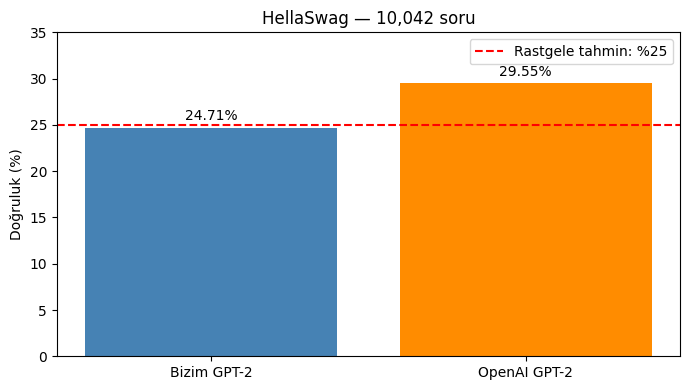

In [35]:
results = pd.DataFrame([custom_result, hf_result])
display(results.round(2))

custom_acc = custom_result["Doğruluk (%)"]
hf_acc = hf_result["Doğruluk (%)"]

gap = hf_acc - custom_acc

print("Rastgele tahminin beklenen doğruluğu: %25.00")
print(f"Bizim modelin %25'e göre farkı: {custom_acc - 25:+.2f} yüzde puan")
print(f"OpenAI modelinin %25'e göre farkı: {hf_acc - 25:+.2f} yüzde puan")

if gap >= 0:
    print(f"Bizim model OpenAI GPT-2'nin {gap:.2f} yüzde puan gerisinde.")
else:
    print(f"Bizim model OpenAI GPT-2'nin {-gap:.2f} yüzde puan önünde.")

plt.figure(figsize=(7, 4))

bars = plt.bar(
    ["Bizim GPT-2", "OpenAI GPT-2"],
    [custom_acc, hf_acc],
    color=["steelblue", "darkorange"],
)

plt.axhline(
    25,
    color="red",
    linestyle="--",
    label="Rastgele tahmin: %25",
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.ylim(0, max(35, custom_acc + 5, hf_acc + 5))
plt.ylabel("Doğruluk (%)")
plt.title(f"HellaSwag — {len(examples):,} soru")
plt.legend()
plt.tight_layout()
plt.show()